# 01 · The data, duplicates and scaling

**Read first:** `01_theory/03_data_scaling.md`

In this notebook you will:

1. load the 6,497 wines and turn the score 0–10 into three grades
2. find the exact duplicates and see why they must go **before** any split
3. see with your own eyes why k-NN is useless without scaling
4. write z-score and min-max scaling, and see what one outlier does to min-max

Run every cell from top to bottom (Shift+Enter). Change numbers and run again — that is how you learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data")
FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar",
            "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
            "pH", "sulphates", "alcohol", "is_red"]

## 1. Loading

The two files use `;` as the separator and have a header line. We read them with numpy,
add a 12th column `is_red` (1 for red, 0 for white), and keep the score separately.

In [2]:
def load(path, is_red):
    raw = np.genfromtxt(path, delimiter=";", skip_header=1)
    X = raw[:, :11]
    X = np.column_stack([X, np.full(len(X), float(is_red))])
    score = raw[:, 11].astype(int)
    return X, score

Xr, sr = load(DATA / "winequality-red.csv", is_red=1)
Xw, sw = load(DATA / "winequality-white.csv", is_red=0)
X = np.vstack([Xr, Xw])
score = np.concatenate([sr, sw])
print("red:", len(Xr), " white:", len(Xw), " total:", len(X), " features:", X.shape[1])

red: 1599  white: 4898  total: 6497  features: 12


## 2. From scores to grades

| score | grade |
|---|---|
| 3, 4, 5 | 0 = low |
| 6 | 1 = medium |
| 7, 8, 9 | 2 = high |

In [3]:
def to_grade(score):
    return np.where(score <= 5, 0, np.where(score == 6, 1, 2))

y = to_grade(score)
values, counts = np.unique(score, return_counts=True)
print("scores:", dict(zip(values.tolist(), counts.tolist())))
for g, name in enumerate(["low", "medium", "high"]):
    print(f"{name:7s} {np.sum(y == g):5d}  ({np.mean(y == g):.1%})")

scores: {3: 30, 4: 216, 5: 2138, 6: 2836, 7: 1079, 8: 193, 9: 5}
low      2384  (36.7%)
medium   2836  (43.7%)
high     1277  (19.7%)


Notice how few wines have score 3 or 9. That is why we use three grades: no method can learn a
class from five examples.

## 3. The duplicate trap

Some rows are **exact copies** of other rows (same 12 values *and* same score).
Let us count them. The trick: turn each row into a tuple and remember the first time we saw it.

In [4]:
def drop_exact_duplicates(X, y):
    """Return (X_unique, y_unique, n_dropped). Keeps the FIRST copy, keeps the order."""
    seen = set()
    keep = []
    for i in range(len(X)):
        key = tuple(X[i]) + (y[i],)
        if key not in seen:
            seen.add(key)
            keep.append(i)
    keep = np.array(keep)
    return X[keep], y[keep], len(X) - len(keep)

Xu, su, dropped = drop_exact_duplicates(X, score)
yu = to_grade(su)
print("dropped", dropped, "duplicates ->", len(Xu), "unique wines")

dropped 1177 duplicates -> 5320 unique wines


**Why does it matter for k-NN?** If a wine and its twin end up one in training and one in testing,
the twin is the nearest neighbour at distance **0** with the right answer. Let us *measure* the cheat:
a 1-NN tested on wines that have a twin in the training set.

In [5]:
rng = np.random.default_rng(0)
idx = rng.permutation(len(X))
train, test = idx[:5000], idx[5000:]

def nearest_distance(X_train, x):
    return np.min(np.sqrt(((X_train - x) ** 2).sum(axis=1)))

zero = sum(nearest_distance(X[train], X[i]) == 0 for i in test)
print(f"{zero} of {len(test)} test wines have an exact twin in training ({zero/len(test):.0%})")

407 of 1497 test wines have an exact twin in training (27%)


More than a quarter of the test wines are "predicted" by looking up their own copy. That is not learning,
and it inflates the score. So: **remove duplicates first, then split.** From now on we use `Xu, yu`.

## 4. Why scaling is not optional

Look at the ranges of the features:

In [6]:
for name, lo, hi, sd in zip(FEATURES, Xu.min(0), Xu.max(0), Xu.std(0)):
    print(f"{name:22s} min {lo:9.3f}   max {hi:9.3f}   std {sd:8.3f}")

fixed acidity          min     3.800   max    15.900   std    1.320
volatile acidity       min     0.080   max     1.580   std    0.168
citric acid            min     0.000   max     1.660   std    0.147
residual sugar         min     0.600   max    65.800   std    4.500
chlorides              min     0.009   max     0.611   std    0.037
free sulfur dioxide    min     1.000   max   289.000   std   17.803
total sulfur dioxide   min     6.000   max   440.000   std   56.769
density                min     0.987   max     1.039   std    0.003
pH                     min     2.720   max     4.010   std    0.160
sulphates              min     0.220   max     2.000   std    0.150
alcohol                min     8.000   max    14.900   std    1.186
is_red                 min     0.000   max     1.000   std    0.436


Total sulfur dioxide has a standard deviation of ~56; chlorides ~0.035; density ~0.003.
In a Euclidean distance the **big** numbers win. Let us see how much each feature contributes to the
squared distance between two random wines, before and after scaling.

In [7]:
def contribution(Xs, n_pairs=2000, seed=1):
    r = np.random.default_rng(seed)
    a = Xs[r.integers(len(Xs), size=n_pairs)]
    b = Xs[r.integers(len(Xs), size=n_pairs)]
    sq = (a - b) ** 2                       # per-feature squared differences
    return sq.sum(0) / sq.sum()             # share of the total

raw_share = contribution(Xu)
for name, s in sorted(zip(FEATURES, raw_share), key=lambda t: -t[1])[:4]:
    print(f"{name:22s} {s:6.1%}")

total sulfur dioxide    90.0%
free sulfur dioxide      9.2%
residual sugar           0.6%
fixed acidity            0.0%


Sulfur dioxide alone is almost the whole distance. Without scaling, "the nearest wine" means
"the wine with the most similar sulfur dioxide", and the other ten features are ignored.

## 5. z-score scaling

$$ z = \frac{x - \text{mean}}{\text{std}} $$

After it, every feature has mean 0 and standard deviation 1. A constant column would divide by 0,
so its std is replaced by 1.

means: [ 0. -0.  0. -0.  0. -0. -0.  0.  0. -0. -0.  0.]
stds:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


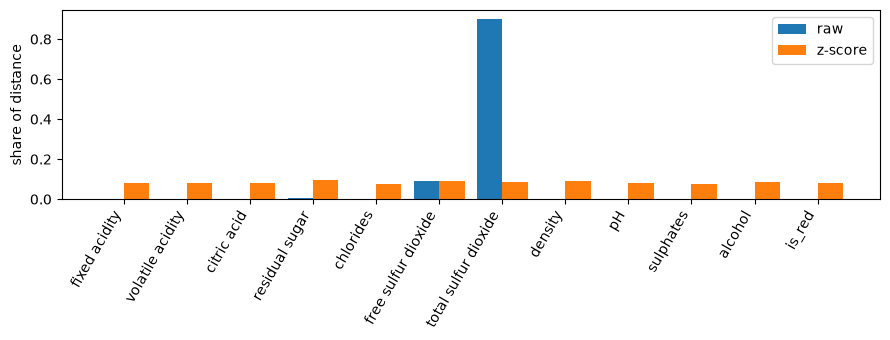

In [8]:
class ZScore:
    def fit(self, X):
        self.mean = X.mean(axis=0)
        std = X.std(axis=0)
        self.std = np.where(std == 0, 1.0, std)
        return self

    def transform(self, X):
        return (X - self.mean) / self.std

Z = ZScore().fit(Xu).transform(Xu)
print("means:", np.round(Z.mean(0), 6))
print("stds: ", np.round(Z.std(0), 6))

z_share = contribution(Z)
fig, ax = plt.subplots(figsize=(9, 3.5))
pos = np.arange(len(FEATURES))
ax.bar(pos - 0.2, raw_share, 0.4, label="raw")
ax.bar(pos + 0.2, z_share, 0.4, label="z-score")
ax.set_xticks(pos, FEATURES, rotation=60, ha="right")
ax.set_ylabel("share of distance")
ax.legend()
plt.tight_layout()
plt.show()

After z-score every feature has a say. (`is_red` gets a large share because it is 0/1 — the
colour really is a big difference between two wines.)

## 6. min-max, and the outlier problem

$$ z = \frac{x - \min}{\max - \min} $$

Simple — but **one** extreme wine sets the whole scale.

In [9]:
class MinMax:
    def fit(self, X):
        self.lo = X.min(axis=0)
        rng_ = X.max(axis=0) - self.lo
        self.range = np.where(rng_ == 0, 1.0, rng_)
        return self

    def transform(self, X):
        return (X - self.lo) / self.range

col = FEATURES.index("total sulfur dioxide")
mm = MinMax().fit(Xu).transform(Xu)[:, col]
print(f"max total SO2: {Xu[:, col].max():.0f}   99% of wines are below {np.percentile(Xu[:, col], 99):.0f}")
print(f"after min-max, 99% of wines are squeezed into [0, {np.percentile(mm, 99):.2f}]")

max total SO2: 440   99% of wines are below 240
after min-max, 99% of wines are squeezed into [0, 0.54]


## 7. The rule that matters: fit on training rows only

The mean and std are **learned**. Learn them from the training rows, then apply the *same* numbers
to the test rows. Compare:

In [10]:
perm = np.random.default_rng(2).permutation(len(Xu))
train, test = perm[:4256], perm[4256:]          # 80% / 20%

right = ZScore().fit(Xu[train])          # learned from training only
Xtr, Xte = right.transform(Xu[train]), right.transform(Xu[test])

wrong = ZScore().fit(Xu)                 # learned from EVERYTHING - leaks the test rows
print("difference in the learned means (right vs wrong):")
print(np.round(right.mean - wrong.mean, 4))

difference in the learned means (right vs wrong):
[-1.300e-03 -1.000e-03  1.400e-03  5.410e-02  2.000e-04  2.050e-01
  4.387e-01  0.000e+00 -2.600e-03  7.000e-04 -7.600e-03 -4.500e-03]


The difference is small — but it is a leak, and an examiner will ask. In the project, scaling is
fitted **inside every fold**.

## ✍️ Try it yourself

1. Change the grade mapping so score 6 counts as "high". How do the class shares change?
2. In section 4, which feature is second after sulfur dioxide? Why does density contribute almost nothing?
3. Compute the share of distance after **min-max** instead of z-score. Which feature dominates now?

Then go to `03_exercises/` and solve exercises 1–4.